# Neural Networks

## Recap: where we left off

- **Linear/Logistic Regression:** parametric models with one coefficient per feature
- **KNN:** an instance-based model that predicts from the nearest accounts
- **Random Forest:** an average of many decision trees, with no scaling needed

## What's different in this notebook

- **A neural network learns its own features.** Hidden layers combine the inputs into new features, and the output layer predicts from those
- **It is trained by gradient descent.** Backpropagation computes how each weight should change to reduce the loss
- **Scaling is needed again**, as in KNN, because the weights are learned by gradient descent
- **There are many hyperparameters:** layers, neurons, learning rate, batch size and epochs
- **Overfitting is a central risk**, so we use dropout and early stopping
- **One network can predict several targets at once.** This is multi-task learning, and it is the main new idea of this notebook

## What this notebook does

- Repeats the same setup as before, with scaling
- **Single task:** a network for `repayment_probability`, covering activations, batch normalisation, dropout and early stopping
- **Threshold tuning:** moving the 0.5 cutoff, shown with precision-recall curves
- **Multi-task:** one network with a shared trunk and five output heads, for all five targets, with loss weighting
- Compares the results with the earlier notebooks
- Uses **Keras 3**

## 1. Setup and Data Preparation

### 1.1 Imports and loading the data

- The backend is set to PyTorch **before** Keras is imported. If `import keras` comes first, Keras ignores the setting
- Install the packages once with `pip install keras torch`

In [1]:
import os                           # sets the environment variable that selects Keras' backend
os.environ["KERAS_BACKEND"] = "torch"  # must be set before keras is imported, otherwise Keras ignores it

import pandas as pd                 # DataFrame operations: loading, filtering, joining
import numpy as np                  # numeric arrays and math (log/exp transforms, NaN handling)
import matplotlib.pyplot as plt     # base plotting
import seaborn as sns               # statistical plots (heatmaps, distribution plots) built on matplotlib
import sklearn                      # imported only to print its version
import torch                        # the backend Keras runs on; imported here to print its version
import keras                        # high-level API for building and training neural networks

# Record the versions, so results can be tied to a setup
print('pandas:', pd.__version__, '| numpy:', np.__version__, '| scikit-learn:', sklearn.__version__)
print('keras:', keras.__version__, '| torch:', torch.__version__, '| backend:', keras.backend.backend())

# Load the feature matrix produced by the EDA notebook. One row per account,
# features and all five targets already joined, split label already assigned
DATA_DIR = "data/"
master = pd.read_pickle(DATA_DIR + 'cleaned_dataset.pkl')

print()
print(f'Loaded: {master.shape[0]:,} rows, {master.shape[1]} columns')
print()
print('Split sizes:')
print(master['split'].value_counts())

pandas: 3.0.3 | numpy: 2.4.6 | scikit-learn: 1.9.1
keras: 3.15.1 | torch: 2.14.1+cpu | backend: torch

Loaded: 13,945 rows, 31 columns

Split sizes:
split
train      8968
val        3115
test       1547
unknown     315
Name: count, dtype: int64


### 1.2 Preparing the data

Same steps as in the earlier notebooks, in one cell:

- Drop the accounts with no split assigned (outside the date ranges defined in the EDA notebook)
- One-hot encode the nominal columns, with the encoder **fit on train only**
- Define the feature set 
- Drop the few rows with missing feature values

In [2]:
##########################################################
## Drop unassigned accounts, encode, define the feature   ##
## set, drop missing values                               ##
##########################################################
from sklearn.preprocessing import OneHotEncoder  # encodes nominal variables as dummy columns, fit on train only to avoid leakage

# --- Drop accounts with no split assigned ---
master = master[master['split'] != 'unknown'].copy()  # they cannot be assigned to train, validation or test

# --- One-hot encode the remaining nominal variables ---
nominal_cols = ['debt_type', 'status', 'city', 'gender', 'household_type',
                'employment_status', 'urban_category', 'country_of_origin',
                'born_in_netherlands']
nominal_cols = [c for c in nominal_cols if c in master.columns]  # keep only columns that exist, avoids a KeyError

# Fit the encoder on the train rows only. fillna('unknown').astype(str) gives
# every missing value an explicit category and avoids mixing bool with str
train_data = master[master['split'] == 'train']
enc = OneHotEncoder(sparse_output=False, handle_unknown='ignore', drop='first')
enc.fit(train_data[nominal_cols].fillna('unknown').astype(str))

# Apply the train-fitted encoder to the full table (train + val + test)
encoded = enc.transform(master[nominal_cols].fillna('unknown').astype(str))
encoded_cols = enc.get_feature_names_out(nominal_cols)  # names like 'debt_type_Credit card'

# Attach the dummy columns to master, keeping master's index so rows line up
encoded_df = pd.DataFrame(encoded, columns=list(encoded_cols), index=master.index)
master = pd.concat([master, encoded_df], axis=1)

# --- Define the feature set ---
# Numeric features engineered in the EDA notebook (log-transformed amounts,
# dates, ordinal-encoded categoricals, and data-quality flags)
numeric_features = ['log_original_amount', 'log_outstanding_balance', 'log_days_past_due',
                    'missed_payments', 'interest_rate', 'broken_arrangements',
                    'age_at_default', 'default_month', 'default_year',
                    'income_band_encoded', 'education_level_encoded',
                    'balance_capped', 'default_date_imputed']
dummy_features = list(encoded_cols)               # one-hot dummy columns
feature_cols = numeric_features + dummy_features  # the full feature list used in this notebook

# --- Drop rows with missing feature values ---
# log_days_past_due and broken_arrangements still have a few nulls that the
# EDA notebook never imputed, under 1% of every split
rows_before = len(master)
master = master.dropna(subset=feature_cols).copy()  # drop rows with any missing feature value
rows_dropped = rows_before - len(master)

print(f'One-hot encoded {len(nominal_cols)} columns into {len(encoded_cols)} dummy columns')
print(f'Total features: {len(feature_cols)}')
print(f'Dropped {rows_dropped} rows with missing feature values ({rows_dropped/rows_before*100:.2f}% of data)')
print()
print('Split sizes after dropping:')
print(master['split'].value_counts())

One-hot encoded 9 columns into 51 dummy columns
Total features: 64
Dropped 109 rows with missing feature values (0.80% of data)

Split sizes after dropping:
split
train    8894
val      3090
test     1537
Name: count, dtype: int64


### 1.3 Extracting train, validation, and test, and scaling

- We use all three splits: the validation split lets us watch the loss while training and stop early, and test is used only at the end
- **Scaling is needed**, because the weights are learned by gradient descent. Features on very different scales make the loss surface hard to descend
- The scaler is **fit on train only**, as in the KNN notebook

In [3]:
##########################################################
## Extract train, validation, and test, then scale      ##
##########################################################
from sklearn.preprocessing import StandardScaler  # standardises features to mean 0, std 1; needed because the weights are learned by gradient descent

# The original splits, as assigned in the EDA notebook
df_train = master[master['split'] == 'train']  # rows the network is trained on
df_val   = master[master['split'] == 'val']    # rows used to monitor the loss during training
df_test  = master[master['split'] == 'test']   # touched only for the final evaluation

X_train = df_train[feature_cols]  # train features, unscaled
X_val   = df_val[feature_cols]    # validation features, unscaled
X_test  = df_test[feature_cols]   # test features, unscaled

print(f'X_train: {X_train.shape}, X_val: {X_val.shape}, X_test: {X_test.shape}')

# Fit the scaler on train only, then apply it to train, validation and test
scaler = StandardScaler()
scaler.fit(X_train)  # fit on train only, same rule as every other transform in this project

# astype('float32'): Keras works in 32-bit floats, and this converts the bool flag columns too
X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=feature_cols, index=X_train.index).astype('float32')
X_val_scaled   = pd.DataFrame(scaler.transform(X_val),   columns=feature_cols, index=X_val.index).astype('float32')
X_test_scaled  = pd.DataFrame(scaler.transform(X_test),  columns=feature_cols, index=X_test.index).astype('float32')

X_train: (8894, 64), X_val: (3090, 64), X_test: (1537, 64)


## 2. A Single-Task Network

### 2.1 How a network is trained: a quick reminder

- **Forward pass:** each layer computes a weighted sum of its inputs and applies an activation. ReLU in the hidden layers, and a sigmoid at the output, which gives P(repays) between 0 and 1
- **Loss:** for a binary target we use **binary cross-entropy**, the same loss as logistic regression. Without the hidden layers, our network would be a logistic regression
- **Backpropagation:** computes how much each weight contributed to the loss, so the optimiser knows which way to change it
- **Optimiser (Adam):** updates the weights in small steps, with the step size set by the **learning rate**
- **Batch and epoch:** the weights are updated after each **batch** of rows. One pass over all training rows is one **epoch**
- **Validation loss:** we track it after every epoch. Training loss keeps falling as the network memorises the training rows, so a validation loss that starts rising signals overfitting

We first predict `repayment_probability`, the classification target.

In [4]:
##########################################################
## Define the target: classification labels per split   ##
##########################################################
# Labels for the classification target, taken from the same original splits.
# astype('float32') because Keras works in 32-bit floats
y_train_clf = df_train['repayment_probability'].astype('float32')  # train labels
y_val_clf   = df_val['repayment_probability'].astype('float32')    # validation labels
y_test_clf  = df_test['repayment_probability'].astype('float32')   # test labels (not used until the final evaluation)

print(f'y_train_clf: {y_train_clf.shape}, y_val_clf: {y_val_clf.shape}, y_test_clf: {y_test_clf.shape}')
print()
print('Class balance (train):')
print((y_train_clf.value_counts(normalize=True) * 100).round(1))

y_train_clf: (8894,), y_val_clf: (3090,), y_test_clf: (1537,)

Class balance (train):
repayment_probability
0.0    74.6
1.0    25.4
Name: proportion, dtype: float64


### 2.2 Defining and compiling the network

- **Architecture:** the input layer has one node per feature, then one hidden layer with ReLU, then a single sigmoid output
- **Loss:** binary cross-entropy, with Adam as the optimiser
- **Class imbalance:** the logistic regression and the forest used `class_weight='balanced'`. Keras has the same idea, passed to `.fit()` as `class_weight={0: w0, 1: w1}`, with weights computed from the train labels, which is the formula we showed in the EDA notebook
- A network that starts out untrained gives different results each time, so we fix the seed to make the run repeatable

Documentation: [Keras Sequential model](https://keras.io/guides/sequential_model/)

In [5]:
##########################################################
## Define and compile the first network                  ##
##########################################################
from keras.models import Sequential  # a model built as a plain stack of layers
from keras.layers import Dense, Input  # Dense: fully connected layer; Input: declares the number of features

keras.utils.set_random_seed(42)  # fixes the seeds of Python, numpy and the backend, so the run is repeatable

simple_nn = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),  # one input node per feature
    Dense(32, activation='relu'),             # hidden layer: 32 neurons with ReLU
    Dense(1, activation='sigmoid'),           # output: P(repays), between 0 and 1
])

simple_nn.compile(loss='binary_crossentropy',  # the same loss as logistic regression
                  optimizer='adam')            # adaptive-step optimiser

simple_nn.summary()  # layers, output shapes and number of weights

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,113 (8.25 KB)

 Trainable params: 2,113 (8.25 KB)

 Non-trainable params: 0 (0.00 B)

### 2.3 Class weights

Only 25.4% of the accounts in the train split repay within 90 days, so the classes are imbalanced. Without a correction, a network can score well by predicting "no repayment" for almost everyone.

- **Class weights** make a mistake on a repayer count more in the loss than a mistake on a non-repayer
- We use the same formula as `class_weight='balanced'` in the earlier notebooks, which weights each class by the inverse of its frequency:

$$w_c = \frac{n_{samples}}{n_{classes} \times n_{samples,\ c}}$$

- The weights are passed to `.fit()` in the next section. We compute them from the **train** labels only
- Other methods exist, such as resampling the data with SMOTE, but we use class weights throughout, as in the earlier notebooks

In [6]:
##########################################################
## Class weights from the train labels                  ##
##########################################################
# 'balanced' formula: n_samples / (n_classes * n_samples_in_class)
n_train = len(y_train_clf)
class_weight_clf = {0: n_train / (2 * (y_train_clf == 0).sum()),  # weight of non-repayers
                    1: n_train / (2 * (y_train_clf == 1).sum())}  # weight of repayers, larger because they are the minority
print(class_weight_clf)

{0: np.float64(0.6701326100060278), 1: np.float64(1.9694419840566872)}


### 2.4 Training and the loss curves

- We train for up to 100 epochs, passing the validation set so Keras records the validation loss after every epoch
- **Class weights apply to the training loss only.** To make the validation loss comparable with the training loss, we also pass per-row weights for the validation set
- If the training loss keeps falling while the validation loss rises, the network is memorising the training rows, which is overfitting
- - Keras prints the training and validation loss after every epoch. Watch how they change as training goes on

Epoch 1/100
139/139 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 0.6632 - val_loss: 0.6790
Epoch 2/100
139/139 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.5557 - val_loss: 0.6645
Epoch 3/100
139/139 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 0.5332 - val_loss: 0.6540
Epoch 4/100
139/139 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 0.5196 - val_loss: 0.6525
Epoch 5/100
139/139 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 0.5092 - val_loss: 0.6491
Epoch 6/100
139/139 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 0.4995 - val_loss: 0.6414
Epoch 7/100
139/139 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 0.4905 - val_loss: 0.6379
Epoch 8/100
139/139 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 0.4824 - val_loss: 0.6339
Epoch 9/100
139/139 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 0.4757 - val_loss: 0.6221
Epoch 10/100
139/139 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 0.4682 - val_loss: 0.6241
Epoch 11/100
139/139 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 0.4625 - val_loss: 0.6155
Epoch 12/100
139/139 ━━━━━━━━━

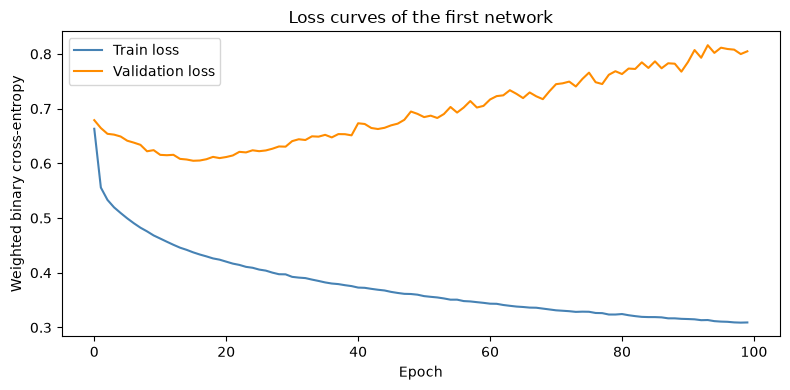

Lowest validation loss at epoch 16


In [7]:
##########################################################
## Train with a validation set and plot the loss curves  ##
##########################################################
# Per-row weights for the validation set, taken from the class weights, so the
# validation loss is weighted the same way as the training loss
w_val = y_val_clf.map(class_weight_clf).astype('float32')

history = simple_nn.fit(
    X_train_scaled, y_train_clf,                      # train features and labels
    validation_data=(X_val_scaled, y_val_clf, w_val), # validation features, labels and row weights
    epochs=100,                                       # maximum number of passes over the training rows
    batch_size=64,                                    # rows per weight update
    class_weight=class_weight_clf,                    # weights in the training loss, from 2.3
)

# Plot the training and validation loss after every epoch
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history.history['loss'],     label='Train loss',      color='steelblue')
ax.plot(history.history['val_loss'], label='Validation loss', color='darkorange')
ax.set_xlabel('Epoch')
ax.set_ylabel('Weighted binary cross-entropy')
ax.set_title('Loss curves of the first network')
ax.legend()
plt.tight_layout()
plt.show()

best_epoch = int(np.argmin(history.history['val_loss'])) + 1  # +1 because epochs are counted from 1
print(f'Lowest validation loss at epoch {best_epoch}')

### What we observe

- **Both losses start high** (training about 0.66, validation about 0.68), as expected for a network that has not been trained
- **The training loss falls steeply in the first few epochs** and then slowly, to about 0.31 at epoch 100
- **The validation loss falls until about epoch 16** (the lowest value is printed by the cell, about 0.61 by eye), then rises steadily to about 0.81 by epoch 100
- **After epoch 16 the network is overfitting:** the training loss keeps falling while the validation loss rises, so the gap between them widens
- The validation curve is noisy, so the exact best epoch depends on the seed and could shift by a few epochs
- The values above are read off the plot, so they are approximate

**QUESTIONS:**

- Why does the training loss keep falling while the validation loss rises after epoch 16?
- Would you stop at the epoch with the lowest validation loss, or use a rule that stops automatically? What are the risks of a noisy validation curve?
- The network has 2,113 weights. How does the size of the network relate to the speed of overfitting? What would you change to overfit later?

### 2.5 Saving and loading a model

- Training takes time, so we save a fitted network and reuse it later without training it again
- `model.save('<name>.keras')` stores the architecture, the weights and the optimiser state in one file
- It does **not** store the training history, so we save the history separately as a JSON file
- `keras.models.load_model(...)` loads the network back. **A loaded model is already trained**, so calling `.fit()` on it continues from its weights, as in the trap we met in 2.4

In [8]:
##################################################################
## Save the fitted network and its history, then load them back ##
##################################################################

import json  # saves the training history as a text file

# Save the network trained in 2.4: architecture, weights and optimiser state in one file
simple_nn.save(DATA_DIR + 'simple_nn_model.keras')

# The history is not part of the saved model, so we store it separately
with open(DATA_DIR + 'simple_nn_history.json', 'w') as handle:
    json.dump(history.history, handle)  # the loss per epoch, as lists of numbers

# Load both back. New names, so the objects from 2.4 are not overwritten
simple_nn_loaded = keras.models.load_model(DATA_DIR + 'simple_nn_model.keras')
with open(DATA_DIR + 'simple_nn_history.json', 'r') as handle:
    history_loaded = json.load(handle)  # a dictionary with 'loss' and 'val_loss'

# Check: the loaded network should give the same predictions as the original
same = np.allclose(simple_nn.predict(X_val_scaled, verbose=0),
                   simple_nn_loaded.predict(X_val_scaled, verbose=0))
print('Loaded network gives the same predictions:', same)
print('Epochs in the loaded history:', len(history_loaded['loss']))

Loaded network gives the same predictions: True
Epochs in the loaded history: 100


### 2.6 Final model: retrain on train + validation, evaluate on test

- The validation loss told us how many epochs to train for (`best_epoch` from 2.4)
- Validation has done its job, so we now train a **new network** with the same architecture on the **fitting data** (train + validation), as in the earlier notebooks
- The scaler and the class weights are recomputed on the fitting data, and test is scaled with that new scaler
- Test is used for the first time here. We report F1, precision and recall as `fit: %.3f, test: %.3f` pairs, with the default 0.5 threshold
- A network starts from random weights, so a different seed gives slightly different scores. It is good practice to repeat the fit several times and average the test scores

-------------------------------------------------------------------------
Single-task network (epochs=16)
F1        - fit: 0.676, test: 0.693
Precision - fit: 0.606, test: 0.625
Recall    - fit: 0.765, test: 0.777
-------------------------------------------------------------------------


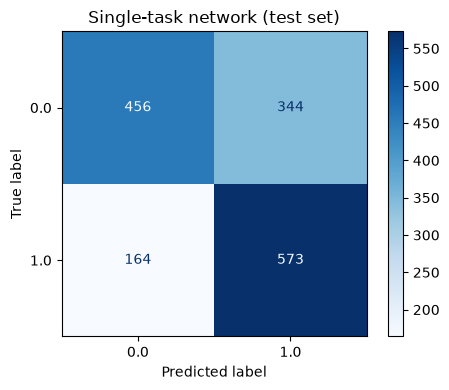

In [9]:
##########################################################
## Retrain on train + validation, evaluate on test      ##
##########################################################
from sklearn.metrics import f1_score, precision_score, recall_score, ConfusionMatrixDisplay  # classification metrics + confusion matrix plot

# Fitting data = the original train and val rows combined
df_fit    = pd.concat([df_train, df_val])
X_fit     = df_fit[feature_cols]                                  # unscaled fitting features
y_fit_clf = df_fit['repayment_probability'].astype('float32')    # fitting labels

# Refit the scaler on the fitting data, then apply it to fit and test.
# New names are used so the scaled versions from 1.3 stay untouched
scaler_fit = StandardScaler().fit(X_fit)
X_fit_scaled      = pd.DataFrame(scaler_fit.transform(X_fit),  columns=feature_cols, index=X_fit.index).astype('float32')   # scaled fitting features
X_test_fit_scaled = pd.DataFrame(scaler_fit.transform(X_test), columns=feature_cols, index=X_test.index).astype('float32')  # test scaled with the fit-data scaler

# Class weights recomputed from the fitting labels, same formula as in 2.3
n_fit = len(y_fit_clf)
class_weight_fit = {0: n_fit / (2 * (y_fit_clf == 0).sum()),  # weight of non-repayers
                    1: n_fit / (2 * (y_fit_clf == 1).sum())}  # weight of repayers

# A new network with the same architecture as simple_nn in 2.2
keras.utils.set_random_seed(42)  # same seed as before, so the run is repeatable
final_nn = Sequential([
    Input(shape=(X_fit_scaled.shape[1],)),  # one input node per feature
    Dense(32, activation='relu'),           # hidden layer: 32 neurons with ReLU
    Dense(1, activation='sigmoid'),         # output: P(repays)
])
final_nn.compile(loss='binary_crossentropy', optimizer='adam')

# Train for the number of epochs the validation curve suggested (best_epoch, from 2.4)
final_nn.fit(X_fit_scaled, y_fit_clf, epochs=best_epoch, batch_size=64,
             class_weight=class_weight_fit, verbose=0)

# P(repays) on the fitting data and on test, then class predictions at the default 0.5 threshold
y_fit_pred  = (final_nn.predict(X_fit_scaled,      verbose=0).ravel() >= 0.5).astype(int)
y_test_pred = (final_nn.predict(X_test_fit_scaled, verbose=0).ravel() >= 0.5).astype(int)

print('-------------------------------------------------------------------------')
print(f'Single-task network (epochs={best_epoch})')
print('F1        - fit: %.3f, test: %.3f' % (f1_score(y_fit_clf, y_fit_pred),        f1_score(y_test_clf, y_test_pred)))
print('Precision - fit: %.3f, test: %.3f' % (precision_score(y_fit_clf, y_fit_pred), precision_score(y_test_clf, y_test_pred)))
print('Recall    - fit: %.3f, test: %.3f' % (recall_score(y_fit_clf, y_fit_pred),    recall_score(y_test_clf, y_test_pred)))
print('-------------------------------------------------------------------------')

# Confusion matrix on test: rows = actual class, columns = predicted class
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test_clf, y_test_pred, ax=ax, cmap='Blues')
ax.set_title('Single-task network (test set)')
plt.tight_layout()
plt.show()

### What we observe

- **Test F1 is 0.693**, with precision 0.625 and recall 0.777
- **Test scores are slightly higher than the fit scores** (F1 0.693 vs 0.676), the same direction as the logistic regression and the forest. A network stopped at its best validation epoch is not memorising the fitting data
- **The network favours recall over precision**, like the logistic regression with `class_weight='balanced'` (recall about 0.80, precision about 0.59). The forest was more balanced (precision 0.725, recall 0.710)
- **Test F1 (0.693) is slightly above the logistic regression (0.679 and 0.681) and below the forest (0.717).** The earlier notebooks were run once each, and this network was trained from one seed, so we cannot say these gaps are larger than the run-to-run noise
- The final model has the best epoch from 2.4 (16 epochs), chosen on validation, and was then trained on train + validation

**QUESTIONS:**

- Test F1 is higher than the fit F1. What could explain this? Check the class balance of the test split against the fitting data
- The network, with one hidden layer, scores about the same as the logistic regression, which has none. What would you try to find out whether the hidden layer adds anything?
- We trained for 16 epochs, chosen on the validation split. The fitting data now includes the validation rows. Is the same number of epochs still the right choice? Why or why not?
- Retrain with five different seeds and average the test F1. How large is the spread? What does it tell you about reporting one score?
- The network's precision is lower than its recall. Using the false-positive vs false-negative cost discussion from the EDA notebook, would you move the 0.5 threshold? In which direction?

### 2.7 Hyperparameter tuning: neurons and batch size

- A network has many hyperparameters. See [grid search hyperparameters for deep learning models](https://machinelearningmastery.com/grid-search-hyperparameters-deep-learning-models-python-keras/). Here we tune two: the **number of neurons** in the hidden layer and the **batch size**
- We do not tune the number of epochs. **Early stopping** ends training when the validation loss has not improved for 3 epochs (`patience=3`)
- We use [Keras Tuner](https://keras.io/guides/keras_tuner/getting_started/), which replaces the older scikit-learn wrappers for Keras models. A `HyperModel` class defines how the network is built (`build`) and how it is fit (`fit`)
- **Random search** tries a random subset of all combinations: 6 trials out of 4 neuron counts x 3 batch sizes = 12
- Each trial is trained on train and scored on the class-weighted validation loss, as in 2.4. Install the package once with `pip install keras-tuner`

In [10]:
##########################################################
## Hyperparameter tuning with Keras Tuner                ##
##########################################################
import tempfile           # creates a fresh temporary folder for the trial files
import keras_tuner as kt  # hyperparameter search for Keras models

class MyTuner(kt.HyperModel):
    """Defines the search space: how each network is built and how it is fit."""

    def build(self, hp):
        """Builds and compiles one network for one choice of hyperparameters.

        Args:
            hp (kt.HyperParameters): Object that holds the value chosen for
                each hyperparameter in this trial.

        Returns:
            keras.Model: A compiled network with one hidden layer.
        """
        neurons = hp.Int('neurons', min_value=16, max_value=64, step=16)  # search space: 16, 32, 48 or 64 neurons
        model = Sequential([
            Input(shape=(X_train_scaled.shape[1],)),  # one input node per feature
            Dense(neurons, activation='relu'),        # hidden layer, size chosen by the tuner
            Dense(1, activation='sigmoid'),           # output: P(repays)
        ])
        model.compile(loss='binary_crossentropy', optimizer='adam')
        return model

    def fit(self, hp, model, *args, **kwargs):
        """Fits the network, with the batch size chosen as a hyperparameter.

        Args:
            hp (kt.HyperParameters): Object that holds this trial's choices.
            model (keras.Model): The network returned by build().
            *args, **kwargs: Passed on to model.fit (data, epochs, callbacks).

        Returns:
            keras.callbacks.History: The training history of this trial.
        """
        return model.fit(*args,
                         batch_size=hp.Choice('batch_size', [32, 64, 128]),  # search space for the batch size
                         **kwargs)

keras.utils.set_random_seed(42)  # fixes the seeds, so the search is repeatable

tuner = kt.GridSearch(
    MyTuner(),
    objective='val_loss',                 # the weighted validation loss, lower is better
    seed=42,
    directory=tempfile.mkdtemp(),         # a new empty folder on every run, so no old folder has to be deleted
    project_name='simple_nn_grid',
)

tuner.search(X_train_scaled, y_train_clf,                        # train features and labels
             validation_data=(X_val_scaled, y_val_clf, w_val),   # weighted validation loss, as in 2.4
             epochs=100,                                         # upper limit, early stopping ends each trial sooner
             class_weight=class_weight_clf,                      # class weights in the training loss, from 2.3
             callbacks=[keras.callbacks.EarlyStopping('val_loss', patience=3)])  # stop after 3 epochs without improvement

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]  # hyperparameters of the best trial
print(f"Best number of neurons: {best_hps.get('neurons')}")
print(f"Best batch size:        {best_hps.get('batch_size')}")

tuner.results_summary(num_trials=12)  # all 12 trials of the grid, best first

Trial 12 Complete [00h 00m 09s]
val_loss: 0.6068518757820129

Best val_loss So Far: 0.5927839875221252
Total elapsed time: 00h 04m 30s
Best number of neurons: 32
Best batch size:        64
Results summary
Results in C:\Users\nakbu\AppData\Local\Temp\tmp53f2lqd4\simple_nn_grid
Showing 12 best trials
Objective(name="val_loss", direction="min")

Trial 0004 summary
Hyperparameters:
neurons: 32
batch_size: 64
Score: 0.5927839875221252

Trial 0002 summary
Hyperparameters:
neurons: 16
batch_size: 128
Score: 0.5957539677619934

Trial 0007 summary
Hyperparameters:
neurons: 48
batch_size: 64
Score: 0.5981994867324829

Trial 0001 summary
Hyperparameters:
neurons: 16
batch_size: 64
Score: 0.600067138671875

Trial 0006 summary
Hyperparameters:
neurons: 48
batch_size: 32
Score: 0.6009079217910767

Trial 0003 summary
Hyperparameters:
neurons: 32
batch_size: 32
Score: 0.6038423180580139

Trial 0010 summary
Hyperparameters:
neurons: 64
batch_size: 64
Score: 0.6044896841049194

Trial 0009 summary
Hyperp

**QUESTIONS:**
- Look at the validation loss of the 12 trials. How large is the difference between the best and the worst? How would you check whether the best trial is really better, or just lucky? Look up the `executions_per_trial` argument of Keras Tuner
- Which matters more here, the number of neurons or the batch size? How would you decide from the table?
- Early stopping with `patience=3` replaced tuning the number of epochs. What happens if the patience is 1? What if it is 20?
- The tuner scored each trial on a single validation split. How could you tune with cross-validation, and what would it cost?

## 3. Activation Functions

- A neuron first computes a weighted sum $z$ of its inputs, then applies an **activation function** $f$ to it: $a = f(z)$
- **Without activation functions, a network is just a linear model.** Each layer would multiply by a matrix, and a product of matrices is another matrix: $W_2(W_1 x) = (W_2 W_1)x$. Activation functions add **non-linearity**, which lets hidden layers capture curved relationships and interactions

| Name | Formula | Range | Typical use |
|---|---|---|---|
| ReLU | $\max(0, z)$ | $[0, \infty)$ | hidden layers |
| Sigmoid | $\frac{1}{1 + e^{-z}}$ | $(0, 1)$ | output for a binary target |
| Tanh | $\frac{e^z - e^{-z}}{e^z + e^{-z}}$ | $(-1, 1)$ | older hidden layers |
| Linear | $z$ | $(-\infty, \infty)$ | output for a regression target |
| Softmax | $\frac{e^{z_i}}{\sum_j e^{z_j}}$ | $(0, 1)$, sums to 1 | output for a multi-class target |

- **Why ReLU in the hidden layers:** it is cheap to compute, and its gradient is 1 for positive $z$. During backpropagation the gradient passes back through every layer, and sigmoid and tanh **saturate**: for large $|z|$ their gradient is close to 0, so it shrinks layer by layer (the **vanishing gradient** problem). A ReLU neuron can get stuck at 0 if its input is negative for every row (a "dead" neuron), which variants such as leaky ReLU address
- **Why sigmoid at a binary output:** it maps any number into $(0, 1)$, which we read as a probability. It is the same function as in logistic regression
- **Why linear at a regression output:** the prediction must be able to take any value, so it is not squashed
- **In our multi-task network:** ReLU in the trunk, sigmoid in three heads, and linear in two heads

Documentation: [Keras activations](https://keras.io/api/layers/activations/)

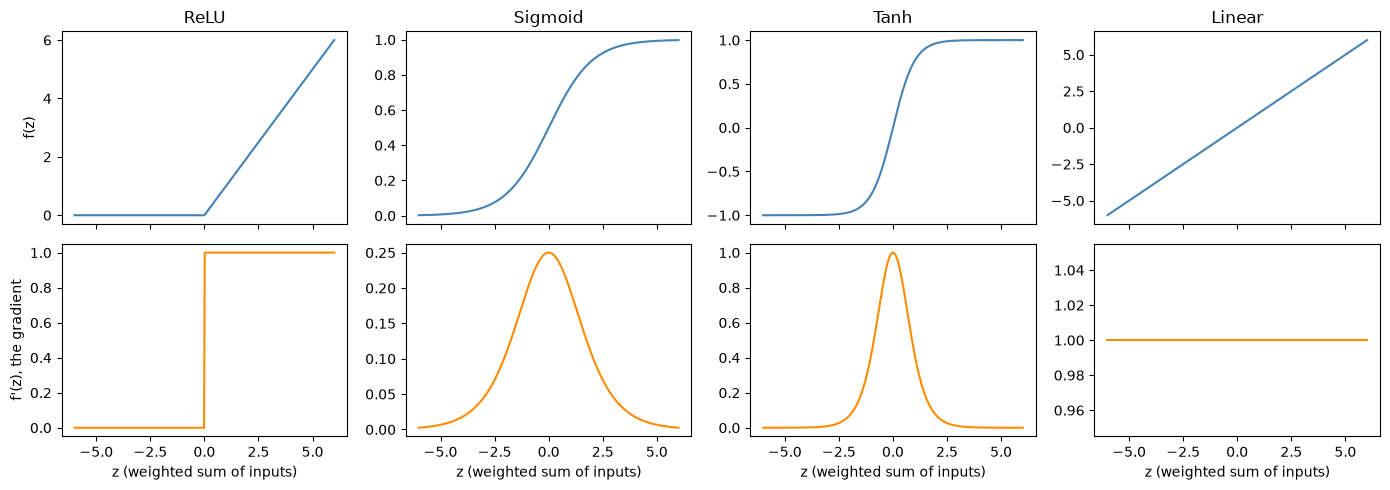

In [11]:
##########################################################
## Plot the activation functions and their derivatives   ##
##########################################################
z = np.linspace(-6, 6, 400)  # a range of inputs to the activation function

sigmoid = 1 / (1 + np.exp(-z))  # sigmoid squashes z into (0, 1)

# name -> (function values, derivative). The derivative is the gradient that backpropagation passes on
activations = {
    'ReLU':    (np.maximum(0, z), (z > 0).astype(float)),    # derivative is 1 for z > 0, else 0
    'Sigmoid': (sigmoid,          sigmoid * (1 - sigmoid)),  # derivative is s(1 - s), at most 0.25
    'Tanh':    (np.tanh(z),       1 - np.tanh(z) ** 2),      # derivative is 1 - tanh^2
    'Linear':  (z,                np.ones_like(z)),          # derivative is always 1
}

fig, axes = plt.subplots(2, 4, figsize=(14, 5), sharex=True)
for col, (name, (values, derivative)) in enumerate(activations.items()):
    axes[0, col].plot(z, values, color='steelblue')       # top row: the activation function
    axes[0, col].set_title(name)
    axes[1, col].plot(z, derivative, color='darkorange')  # bottom row: its derivative
    axes[1, col].set_xlabel('z (weighted sum of inputs)')
axes[0, 0].set_ylabel('f(z)')
axes[1, 0].set_ylabel("f'(z), the gradient")
plt.tight_layout()
plt.show()

**QUESTIONS:**

- Look at the bottom row. Where is the gradient of the sigmoid close to zero? What does that mean for a network with many sigmoid hidden layers?
- Why would a sigmoid output be a poor choice for a regression target such as `log_repayment_amount`?
- Replace `relu` by `linear` in the hidden layer of the first network (2.2) and train it as in 2.4. What kind of model have you built, and how do the loss curves compare?
- Which output activation would you use for a target with three classes?
- A ReLU neuron receives a negative $z$ for every training row. What happens to its output and its gradient? What could you use instead?

## 4. Batch Normalisation

- We standardised the input features before training. **Batch normalisation** does the same thing inside the network, for the inputs of a layer
- For each batch, it computes the mean $\mu_B$ and variance $\sigma_B^2$ of every neuron's values, standardises them, and then rescales them with two **learned** parameters $\gamma$ and $\beta$:

$$\hat{x} = \frac{x - \mu_B}{\sqrt{\sigma_B^2 + \epsilon}}, \qquad y = \gamma \hat{x} + \beta$$

- **Why it helps:** it keeps the values that flow through the network on a stable scale. This usually allows faster and more stable training
- **Training vs prediction:** during training it uses the statistics of the current batch. At prediction time it uses **running averages** collected during training, so a single row can be predicted. Keras handles the switch automatically
- **Placement:** it is often put between the `Dense` layer and the activation, but putting it after the activation is also common
- **A side effect:** every batch has slightly different statistics, which adds a little noise and acts as a mild regulariser
- We add a batch normalisation layer to the first network and compare the loss curves

Documentation: [Keras BatchNormalization](https://keras.io/api/layers/normalization_layers/batch_normalization/)

**Note:** `StandardScaler` standardises the **input features** once, before training. Batch normalisation standardises the **inputs of a layer inside the network**, for every batch, while the weights of the earlier layers keep changing.

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,241 (8.75 KB)

 Trainable params: 2,177 (8.50 KB)

 Non-trainable params: 64 (256.00 B)

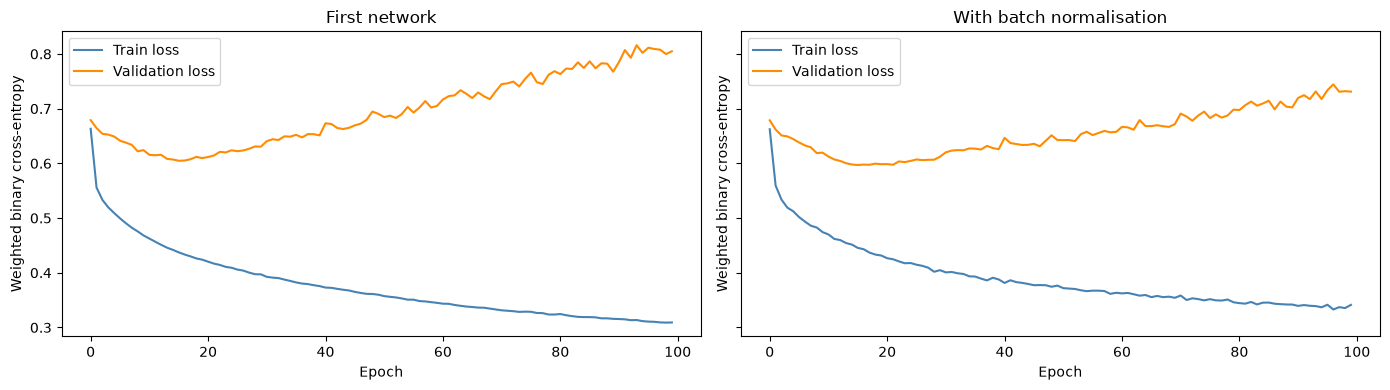

Lowest validation loss, first network:       0.605 at epoch 16
Lowest validation loss, batch normalisation: 0.597 at epoch 16


In [12]:
##########################################################
## A network with batch normalisation, compared with     ##
## the first network                                     ##
##########################################################
from keras.layers import BatchNormalization, Activation  # BatchNormalization: standardises a layer's values per batch; Activation: applies an activation as its own layer

keras.utils.set_random_seed(42)  # same seed as before, so the run is repeatable

bn_nn = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),  # one input node per feature
    Dense(32),                                # the weighted sum only, the activation comes after the normalisation
    BatchNormalization(),                     # standardise the 32 values per batch, then rescale with learned gamma and beta
    Activation('relu'),                       # ReLU, applied to the normalised values
    Dense(1, activation='sigmoid'),           # output: P(repays)
])
bn_nn.compile(loss='binary_crossentropy', optimizer='adam')  # same loss and optimiser as the first network

bn_nn.summary()  # note the trainable and non-trainable parameters of the normalisation layer

history_bn = bn_nn.fit(
    X_train_scaled, y_train_clf,                       # train features and labels
    validation_data=(X_val_scaled, y_val_clf, w_val),  # weighted validation loss, as in 2.4
    epochs=100, batch_size=64,                         # same settings as the first network
    class_weight=class_weight_clf,                     # class weights in the training loss, from 2.3
    verbose=0,                                         # a comparison run, so no per-epoch printout
)

def plot_loss(hist, ax, title):
    """Plots the training and validation loss after every epoch.

    Args:
        hist (keras.callbacks.History): The history returned by model.fit.
        ax (matplotlib.axes.Axes): The axis to draw on.
        title (str): Title of the plot.

    Returns:
        None
    """
    ax.plot(hist.history['loss'],     label='Train loss',      color='steelblue')   # training loss per epoch
    ax.plot(hist.history['val_loss'], label='Validation loss', color='darkorange')  # validation loss per epoch
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Weighted binary cross-entropy')
    ax.set_title(title)
    ax.legend()

# Side by side with the first network (history comes from 2.4), on the same vertical scale
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
plot_loss(history,    axes[0], 'First network')
plot_loss(history_bn, axes[1], 'With batch normalisation')
plt.tight_layout()
plt.show()

print(f'Lowest validation loss, first network:       {min(history.history["val_loss"]):.3f} at epoch {int(np.argmin(history.history["val_loss"])) + 1}')
print(f'Lowest validation loss, batch normalisation: {min(history_bn.history["val_loss"]):.3f} at epoch {int(np.argmin(history_bn.history["val_loss"])) + 1}')

### What we observe

- The lowest validation loss is almost the same with and without batch normalisation (0.605 and 0.597), and both come at epoch 16
- The training loss falls at a similar speed in the first epochs
- After epoch 16 both validation losses rise, but the batch-normalised network's rises less, and its training loss ends higher. By eye, the validation loss ends near 0.73 against 0.81, and the training loss near 0.34 against 0.31
- With one seed per network, we cannot tell whether a difference of 0.008 at the minimum is larger than the run-to-run noise
- A technique that helps in deep networks need not help in a network with one hidden layer and standardised inputs

## 5. Dropout

- **Dropout** is a regularisation technique. During training, at every weight update, each neuron in the layer is **switched off** (its output set to 0) with probability `rate`, chosen at random. A different set of neurons is dropped for every batch
- **Why it helps:** no neuron can rely on a specific other neuron being present, so the network cannot build fragile combinations that only work for the training rows. It behaves a little like training many smaller networks and averaging them, similar in spirit to the random forest
- **Training vs prediction:** dropout is active only during training. At prediction time all neurons are used, and Keras scales the values so that their size stays consistent. You do not need to do anything, since Keras switches it automatically
- **The rate is a hyperparameter.** A common range is 0.1 to 0.5. A higher rate regularises more, and too high a rate makes the network underfit
- We add a dropout layer after the hidden layer of the first network, with a rate of 0.3, and compare the loss curves

Documentation: [Keras Dropout](https://keras.io/api/layers/regularization_layers/dropout/)

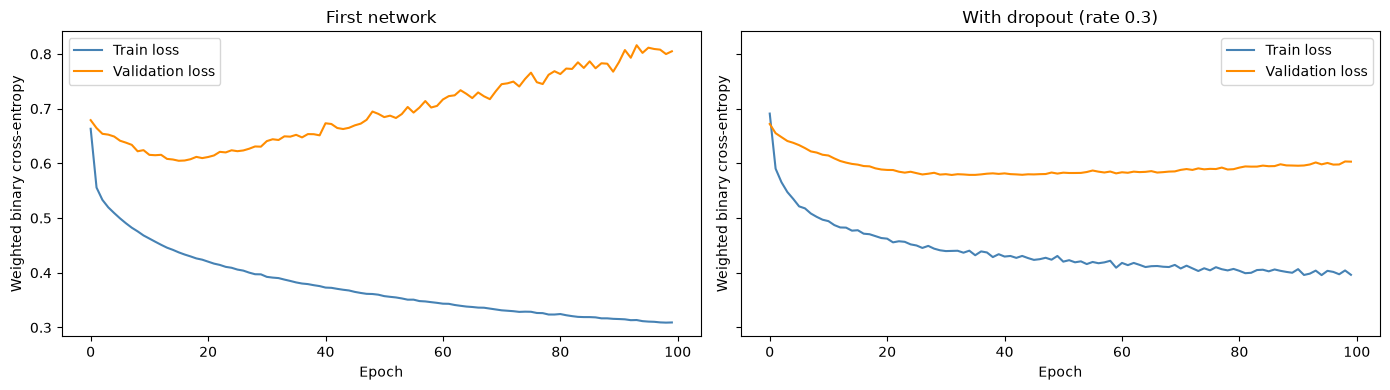

Lowest validation loss, first network: 0.605 at epoch 16
Lowest validation loss, dropout:       0.579 at epoch 32


In [13]:
##########################################################
## A network with dropout, compared with the first       ##
## network                                               ##
##########################################################
from keras.layers import Dropout  # randomly switches off neurons during training

keras.utils.set_random_seed(42)  # same seed as before, so the run is repeatable

dropout_nn = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),  # one input node per feature
    Dense(32, activation='relu'),             # the same hidden layer as the first network
    Dropout(0.3),                             # during training, each of the 32 values is set to 0 with probability 0.3
    Dense(1, activation='sigmoid'),           # output: P(repays)
])
dropout_nn.compile(loss='binary_crossentropy', optimizer='adam')  # same loss and optimiser as the first network

history_dropout = dropout_nn.fit(
    X_train_scaled, y_train_clf,                       # train features and labels
    validation_data=(X_val_scaled, y_val_clf, w_val),  # weighted validation loss, as in 2.4
    epochs=100, batch_size=64,                         # same settings as the first network
    class_weight=class_weight_clf,                     # class weights in the training loss, from 2.3
    verbose=0,                                         # a comparison run, so no per-epoch printout
)

# Side by side with the first network (history comes from 2.4), on the same vertical scale.
# plot_loss comes from the batch normalisation section
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
plot_loss(history,         axes[0], 'First network')
plot_loss(history_dropout, axes[1], 'With dropout (rate 0.3)')
plt.tight_layout()
plt.show()

print(f'Lowest validation loss, first network: {min(history.history["val_loss"]):.3f} at epoch {int(np.argmin(history.history["val_loss"])) + 1}')
print(f'Lowest validation loss, dropout:       {min(history_dropout.history["val_loss"]):.3f} at epoch {int(np.argmin(history_dropout.history["val_loss"])) + 1}')

### What we observe
- The lowest validation loss is **0.579 at epoch 32** with dropout, against 0.605 at epoch 16 without it. The minimum is lower and comes later
- **After the minimum, the validation loss with dropout stays almost flat**, ending near 0.60 at epoch 100. Without dropout it rises steadily to about 0.81
- **The training loss ends higher with dropout** (about 0.40 against 0.31), and falls more slowly. The gap between the two curves is much smaller
- This is one seed per network, so we cannot say how much of a difference of 0.026 at the minimum is noise.

**QUESTIONS:**

- Compare the two loss curves. Does dropout change the gap between the training loss and the validation loss? Where does the validation loss reach its minimum, and how does it behave after that?
- Keras computes the training loss **with** dropout switched on, and the validation loss **without** it. How does this affect a comparison of the two curves?
- Try dropout rates of 0.1, 0.5 and 0.8. What happens at each? How would you choose the rate, and how could you add it to the Keras Tuner search in 2.7?
- Dropout is switched off at prediction time. Why? What would happen to the predictions if it stayed on?
- A random forest and a network with dropout both leave something out at random. What is left out in each, and what is averaged at the end?
- Batch normalisation and dropout both regularise. How are they different? What do you expect if you use both in the same network?
- Increase the hidden layer to 128 neurons, with and without dropout of 0.5. Does dropout let you use a bigger network without overfitting?
- With dropout, the validation loss stays almost flat for a long time. Would you still use early stopping? How would you choose the number of epochs for the final model?





## 6. A Multi-Task Network

### The business problem

The agency does not make one decision per account. It makes several, and each depends on a different prediction:

- **Is it worth contacting this debtor?** `repayment_probability` and `log_repayment_amount`: roughly, the expected value of an account is the chance of repayment times the amount
- **How much effort is needed?** `response_probability`: will the debtor reply to our contact attempts?
- **Is contact risky?** `complaint_risk`: a complaint costs time, and carries regulatory and reputational risk
- **When will the money arrive?** `time_to_repayment`: needed for planning, and only defined for debtors who pay

That is five predictions for every account, all made from the same account information.

### Why one network with five heads?

- **One model to train, deploy and monitor**, in place of five
- **A shared trunk:** the hidden layers learn features that are useful for several targets at once. A target with few positive cases, such as `complaint_risk`, may borrow from related targets
- **Consistent predictions:** all five outputs for an account come from the same internal representation
- **Mild regularisation:** a trunk that has to serve five targets has a harder time memorising the noise of any one of them

### Why it may not help

- **It is not guaranteed to beat five separate models.** Targets can pull the trunk in different directions, which is called **negative transfer**
- **It brings new design choices:** how to weight the five losses, how to put the targets on a comparable scale, and what to do about the missing `time_to_repayment`
- **Each target may need a different model complexity**

So we treat it as a question to test: does the `repayment_probability` head of the multi-task network do better or worse than the single-task network from Section 2?

### The architecture

| Target | Type | Output head |
|---|---|---|
| `repayment_probability` | binary | sigmoid |
| `response_probability` | binary | sigmoid |
| `complaint_risk` | binary | sigmoid |
| `log_repayment_amount` | continuous | linear |
| `time_to_repayment` | continuous, missing for non-payers | linear |

The total loss is a weighted sum of the five losses, with binary cross-entropy for the binary heads and mean squared error for the regression heads:

$$\text{total loss} = w_1 L_{repay\_prob} + w_2 L_{repay\_amt} + w_3 L_{response} + w_4 L_{complaint} + w_5 L_{time}$$

### 6.1 Looking at the five targets

In [14]:
##########################################################
## The five targets: missing values and class balance    ##
##########################################################
binary_targets     = ['repayment_probability', 'response_probability', 'complaint_risk']  # sigmoid heads
regression_targets = ['log_repayment_amount', 'time_to_repayment']                       # linear heads
target_cols_mt     = binary_targets + regression_targets                                 # all five targets

# Share of missing values per target in train
print('Share of missing values (train):')
print(df_train[target_cols_mt].isna().mean().round(3))

# Share of class 1 for each binary target in train
print()
print('Share of class 1 (train):')
print(df_train[binary_targets].mean().round(3))

# Range of the two regression targets in train: they are on very different scales
print()
print(df_train[regression_targets].describe().loc[['min', 'mean', 'max']].round(2))

Share of missing values (train):
repayment_probability    0.000
response_probability     0.000
complaint_risk           0.000
log_repayment_amount     0.000
time_to_repayment        0.746
dtype: float64

Share of class 1 (train):
repayment_probability    0.254
response_probability     0.050
complaint_risk           0.165
dtype: float64

      log_repayment_amount  time_to_repayment
min                   0.00               0.00
mean                  0.96              33.53
max                   6.97              90.00


### What we observe

- Four of the five targets are complete. **`time_to_repayment` is missing for 74.6% of train rows**
- The binary targets are imbalanced to different degrees: `response_probability` has 5.0% class 1, `complaint_risk` 16.5% and `repayment_probability` 25.4%
- `time_to_repayment` runs up to 90 days, and `log_repayment_amount` up to about 7
- `log_repayment_amount` has a minimum of 0, because non-repayers have an amount of 0 and `log1p(0) = 0`


**QUESTIONS:**

- The share of missing `time_to_repayment` equals the share of non-repayers. Check whether the missing rows are exactly the rows with `repayment_probability = 0`. What does the answer imply for the `time_to_repayment` head?
- Only 5% of the accounts have `response_probability = 1`. A class weight of about 10 makes each positive row count ten times as much. What risk does that create for training that head?
- The two regression targets are on very different scales. What would happen to the shared trunk if we trained on the raw values?
- The `log_repayment_amount` head includes the zeros of the non-repayers, while `time_to_repayment` leaves its missing rows out. Is that a consistent choice? What alternatives would you consider?

### 6.2 Preparing the targets

Three preparations before training, as flagged in 6.1:

- **Standardise the two regression targets**, with the mean and standard deviation taken from **train** only. `time_to_repayment` runs up to about 90 days and `log_repayment_amount` only to about 7, so without this the larger scale would dominate the squared error. Predictions are converted back for reporting
- **One class weight per binary head**, from the train labels, with the same formula as in 2.3. Each target has its own class balance, so each head gets its own weights
- **Mask the missing `time_to_repayment`**: its missing values are filled with a placeholder 0, and given a **weight of 0**, so those rows add nothing to that head's loss. We do not impute a target
- Keras accepts one array of weights per output head, passed as a dictionary

In [15]:
##########################################################
## Prepare the targets: standardise, weight and mask     ##
##########################################################
def get_reg_stats(df):
    """Computes the mean and standard deviation of each regression target.

    Args:
        df (pd.DataFrame): The rows to compute the statistics from.

    Returns:
        dict: Regression target -> (mean, std). Missing values are ignored.
    """
    stats = {}                                        # an empty dictionary, one entry per regression target
    for t in regression_targets:
        stats[t] = (df[t].mean(), df[t].std())        # mean() and std() skip the missing values
    return stats

def get_class_weights(df):
    """Computes the 'balanced' class weights of every binary target.

    Args:
        df (pd.DataFrame): The rows to compute the weights from.

    Returns:
        dict: Binary target -> {0: weight, 1: weight}, with the same formula
            as in 2.3: n_samples / (n_classes * n_samples_in_class).
    """
    weights = {}                                      # an empty dictionary, one pair of weights per binary head
    n_rows = len(df)                                  # number of rows
    for t in binary_targets:
        n_pos = df[t].sum()                           # number of class-1 rows
        n_neg = n_rows - n_pos                        # number of class-0 rows
        weights[t] = {0: n_rows / (2 * n_neg),
                      1: n_rows / (2 * n_pos)}
    return weights

def make_labels(df, stats):
    """Builds the label dictionary for one set of rows, with one array per output head.

    Args:
        df (pd.DataFrame): The rows to build labels for.
        stats (dict): Regression target -> (mean, std) used to standardise it.

    Returns:
        dict: Head name -> float32 array. Missing regression values become 0.
    """
    labels = {}
    for t in binary_targets:
        labels[t] = df[t].astype('float32').to_numpy()                 # binary labels as they are
    for t in regression_targets:
        mean, std = stats[t]
        z = (df[t] - mean) / std                                        # standardise with the given statistics
        labels[t] = z.fillna(0).astype('float32').to_numpy()            # placeholder 0 where missing, masked by the weights
    return labels

def make_weights(df, class_weights):
    """Builds the sample weights for one set of rows, with one array per output head.

    Args:
        df (pd.DataFrame): The rows to build weights for.
        class_weights (dict): Binary target -> {0: weight, 1: weight}.

    Returns:
        dict: Head name -> float32 array. Binary heads get the class weight of
            each row's class, regression heads get 1 where the target exists
            and 0 where it is missing.
    """
    weights = {}
    for t in binary_targets:
        weights[t] = df[t].map(class_weights[t]).astype('float32').to_numpy()  # class weight of each row
    for t in regression_targets:
        weights[t] = df[t].notna().astype('float32').to_numpy()                # 1 where the target exists, 0 where missing
    return weights

# --- Apply the functions to train and validation, with the train statistics and class weights ---
reg_stats        = get_reg_stats(df_train)
class_weights_mt = get_class_weights(df_train)
y_train_mt = make_labels(df_train, reg_stats)
y_val_mt   = make_labels(df_val,   reg_stats)
w_train_mt = make_weights(df_train, class_weights_mt)
w_val_mt   = make_weights(df_val,   class_weights_mt)

print('Class weights per binary head (class 0, class 1):')
for t in binary_targets:
    print(f'  {t:<22} {class_weights_mt[t][0]:.3f}, {class_weights_mt[t][1]:.3f}')
print()
print('Share of train rows with weight 0 (masked):')
for t in regression_targets:
    print(f'  {t:<22} {1 - w_train_mt[t].mean():.3f}')

Class weights per binary head (class 0, class 1):
  repayment_probability  0.670, 1.969
  response_probability   0.526, 10.061
  complaint_risk         0.599, 3.038

Share of train rows with weight 0 (masked):
  log_repayment_amount   0.000
  time_to_repayment      0.746


### 6.3 Defining the network

- **One network, five outputs:** a plain `Sequential` model has a single output, so it cannot be the whole network. We build the shared trunk as a `Sequential` model, as before, create five separate output layers (the heads), and connect each head to the output of the trunk
- **Shared trunk:** two hidden layers (64 and 32 neurons, ReLU), each followed by dropout, as in Section 5. All five heads read the same 32 values
- **Five heads:** each is a single output neuron. Three have a sigmoid activation (the binary targets), and two have a linear activation (the standardised regression targets)
- **Connecting:** calling `trunk(inputs)` means "pass the inputs through the trunk". Calling a head on the trunk's output does the same for that head
- **Losses:** binary cross-entropy for the three binary heads, mean squared error for the two regression heads
- **Loss weights:** the weights $w_1, \dots, w_5$ in the total loss balance the heads **against each other**. The class weights from 6.2 balance the classes **within** a head. We start with 1 for every head, because it is the neutral choice: we have no evidence yet about which target the agency values most or which loss is on which scale, so we treat all five alike. We can change the weights later if one head dominates


### The three kinds of weights

| | Class weights | Mask | Loss weights |
|---|---|---|---|
| **What it does** | Balances the two classes **within** one binary head | Switches off the rows where a target is missing | Balances the five heads **against each other** |
| **Applies to** | The three binary heads | `time_to_repayment` (and `log_repayment_amount`, where nothing is missing) | All five heads |
| **Defined in** | 6.2 | 6.2 | 6.3 |
| **Computed from** | The train labels | Whether the target is missing | We choose them |
| **Passed to Keras as** | `sample_weight` | `sample_weight` | `loss_weights` in `compile()` |
| **Value per row** | One weight per class | 1 if the target exists, 0 if missing | None, one number per head |
| **Our values** | `repayment_probability`: 0.670 / 1.969<br>`response_probability`: 0.526 / 10.061<br>`complaint_risk`: 0.599 / 3.038 | 74.6% of train rows are masked for `time_to_repayment`, none for `log_repayment_amount` | 1.0 for every head |

For each head, Keras multiplies every row's loss by that row's sample weight (the class weight or the mask), averages, multiplies by the head's loss weight, and adds the five results into the total loss. 

In [16]:
##########################################################
## Define and compile the multi-task network             ##
##########################################################
from keras.models import Sequential  # a model built as a plain stack of layers
from keras.layers import Dense, Input, Dropout  # Dense: fully connected layer; Input: declares the number of features; Dropout: regularisation

def build_multi_nn(n_features):
    """Builds and compiles the multi-task network: a shared trunk and five heads.

    Args:
        n_features (int): Number of input features.

    Returns:
        keras.Model: A compiled network with one output per target.
    """
    # --- Shared trunk: built with .add(), as in Section 2 ---
    trunk = Sequential()                     # an empty stack of layers
    trunk.add(Dense(64, activation='relu'))  # first shared hidden layer
    trunk.add(Dropout(0.3))                  # dropout, as in Section 5
    trunk.add(Dense(32, activation='relu'))  # second shared hidden layer
    trunk.add(Dropout(0.3))                  # dropout again

    # --- Connect the pieces: the same trunk output feeds every head ---
    inputs = Input(shape=(n_features,), name='features')  # one input node per feature
    shared = trunk(inputs)                                # pass the inputs through the trunk

    outputs = {}                     # one output per head
    losses = {}                      # one loss per head
    loss_weights = {}                # one loss weight per head, all 1 to start with
    for t in binary_targets:
        head = Dense(1, activation='sigmoid', name=t)   # sigmoid: P(class 1), between 0 and 1
        outputs[t] = head(shared)                       # pass the shared values through this head
        losses[t] = 'binary_crossentropy'
        loss_weights[t] = 1.0
    for t in regression_targets:
        head = Dense(1, activation='linear', name=t)    # linear: any real value (the standardised target)
        outputs[t] = head(shared)
        losses[t] = 'mse'
        loss_weights[t] = 1.0

    model = keras.Model(inputs=inputs, outputs=outputs)  # one network, five outputs
    model.compile(optimizer='adam', loss=losses, loss_weights=loss_weights)
    return model

keras.utils.set_random_seed(42)                         # fixes the seeds, so the run is repeatable
multi_nn = build_multi_nn(X_train_scaled.shape[1])      # build the network for the train features
multi_nn.summary()                                      # layers, shapes and number of weights

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ features            │ (None, 64)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_3        │ (None, 32)        │      6,240 │ features[0][0]    │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ complaint_risk      │ (None, 1)         │         33 │ sequential_3[0][… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ log_repayment_amou… │ (None, 1)         │         33 │ sequential_3[0][… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repayment_probabil… │ (None, 1)         │         33 │ sequential_3[0][… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ response_probabili… │ (None, 1)         │         33 │ sequential_3[0][… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_to_repayment   │ (None, 1)         │         33 │ sequential_3[0][… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 6,405 (25.02 KB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 0 (0.00 B)

**QUESTIONS:**
- Why are the three binary heads sigmoid and the two regression heads linear? What would go wrong with a sigmoid on `time_to_repayment`?
- Count the weights of the trunk and of one head. Which part of the network holds most of them?
- All five loss weights are 1. Why might that not be a good balance? Think about the scale of each loss and the class weights
- The trunk is shared. In which situation would you expect this to help a head, and in which to hurt it?

### 6.4 Training

- We train for up to 100 epochs and watch the loss on the validation set, as in 2.4
- **Labels and weights are passed as dictionaries**, with one entry per head, built in 6.2. The class weights and the mask for `time_to_repayment` are both sample weights
- **The validation loss uses the same weights** as the training loss, so the two curves are comparable
- Keras reports the **total loss** (the weighted sum of the five) and the loss of **each head**. We plot both
- Keras prints one long line per epoch for five heads, so we switch the printout off and plot instead

In [17]:
##########################################################
## Train the multi-task network                         ##
##########################################################
history_mt = multi_nn.fit(
    X_train_scaled, y_train_mt,                         # train features and a dictionary of labels, one per head
    sample_weight=w_train_mt,                           # a dictionary of weights, one per head, from 6.2
    validation_data=(X_val_scaled, y_val_mt, w_val_mt), # validation features, labels and weights
    epochs=100,                                         # maximum number of passes over the training rows
    batch_size=64,                                      # rows per weight update
    verbose=0,                                          # five heads give a very long line per epoch, so we plot instead
)

print(list(history_mt.history.keys()))  # the names of the recorded losses, used in the plot below

['complaint_risk_loss', 'log_repayment_amount_loss', 'loss', 'repayment_probability_loss', 'response_probability_loss', 'time_to_repayment_loss', 'val_complaint_risk_loss', 'val_log_repayment_amount_loss', 'val_loss', 'val_repayment_probability_loss', 'val_response_probability_loss', 'val_time_to_repayment_loss']


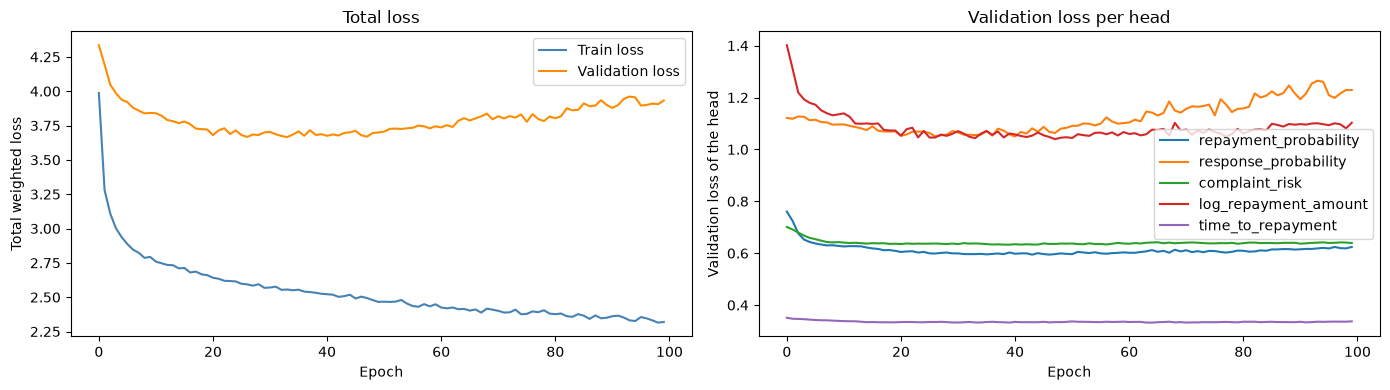

Lowest total validation loss at epoch 34


In [18]:
##########################################################
## Plot the total loss and the loss of each head         ##
##########################################################
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: the total loss, train and validation
axes[0].plot(history_mt.history['loss'],     label='Train loss',      color='steelblue')
axes[0].plot(history_mt.history['val_loss'], label='Validation loss', color='darkorange')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Total weighted loss')
axes[0].set_title('Total loss')
axes[0].legend()

# Right: the validation loss of every head, one line each
for t in target_cols_mt:                                      # loop over the five heads
    key = 'val_' + t + '_loss'                                # the name Keras gives to this head's validation loss
    axes[1].plot(history_mt.history[key], label=t)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Validation loss of the head')
axes[1].set_title('Validation loss per head')
axes[1].legend()

plt.tight_layout()
plt.show()

best_epoch_mt = int(np.argmin(history_mt.history['val_loss'])) + 1  # +1 because epochs are counted from 1
print(f'Lowest total validation loss at epoch {best_epoch_mt}')

**QUESTIONS:**

- Look at the total loss. At which epoch is the validation loss lowest? What happens to the training loss and the validation loss after that?
- Look at the validation loss of each head. Do all five reach their minimum at the same epoch? What does that imply for a single early-stopping rule on the total?
- Which two heads have the highest validation loss? Can you compare the heights of the curves directly? Why or why not?
- `response_probability` starts to rise first. Its class-1 weight is about 10. Could the weight be part of the reason? How would you test it?
- All loss weights are 1. Would you change them? Which ones, in which direction, and how would you check that it helped?

### 6.5 Final multi-task network: retrain on train + validation, evaluate on test

- As in 2.6, the validation split has done its job, so we train a **new network** with the same architecture on the **fitting data** (train + validation), for the number of epochs found in 6.4 (`best_epoch_mt`)
- The standardisation of the two regression targets and the class weights are **recomputed on the fitting data**
- Test is used for the first time here. We report each head on its own scale:
  - **Binary heads:** F1, precision, recall and ROC-AUC, with the 0.5 threshold, as `fit: %.3f, test: %.3f` pairs
  - **`log_repayment_amount`:** MAE, RMSE and R² in **EUR**, after `np.expm1()`
  - **`time_to_repayment`:** MAE, RMSE and R² in **days**, on the rows where the target exists
- One number of epochs is used for all five heads, chosen on the total validation loss

In [19]:
##########################################################
## Retrain on train + validation                         ##
##########################################################
# --- The same functions as in 6.2, now applied to the fitting data ---
reg_stats_fit        = get_reg_stats(df_fit)             # standardisation statistics of the fitting data
class_weights_mt_fit = get_class_weights(df_fit)         # class weights of the fitting data
y_fit_mt = make_labels(df_fit, reg_stats_fit)            # labels of the fitting data
w_fit_mt = make_weights(df_fit, class_weights_mt_fit)    # weights of the fitting data

# --- The same function as in 6.3: a new network, trained for best_epoch_mt epochs (from 6.4) ---
keras.utils.set_random_seed(42)                          # same seed as before, so the run is repeatable
final_multi_nn = build_multi_nn(X_fit_scaled.shape[1])   # a fresh network with the same architecture
final_multi_nn.fit(X_fit_scaled, y_fit_mt,               # fitting features and the dictionary of labels
                   sample_weight=w_fit_mt,               # the dictionary of weights
                   epochs=best_epoch_mt,                 # the number of epochs found in 6.4
                   batch_size=64,
                   verbose=0)                            # no per-epoch printout

In [20]:
##########################################################
##               Evaluation functions                   ##
##########################################################
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score  # classification metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score        # regression metrics

def evaluate_binary(y_true, prob):
    """Computes the classification metrics of one binary head.

    Args:
        y_true (np.ndarray): True labels, 0 or 1.
        prob (np.ndarray): Predicted probability of class 1.

    Returns:
        dict: F1, Precision, Recall (at the 0.5 threshold) and ROC-AUC.
    """
    y_class = (prob >= 0.5).astype(int)                  # class predictions at the 0.5 threshold
    metrics = {}                                         # an empty dictionary for the four metrics
    metrics['F1']        = f1_score(y_true, y_class)
    metrics['Precision'] = precision_score(y_true, y_class)
    metrics['Recall']    = recall_score(y_true, y_class)
    metrics['ROC-AUC']   = roc_auc_score(y_true, prob)   # uses the probabilities, not the classes
    return metrics

def evaluate_regression(y_true, y_pred):
    """Computes the regression metrics of one regression head.

    Args:
        y_true (np.ndarray): True values, on the scale to report.
        y_pred (np.ndarray): Predicted values, on the same scale.

    Returns:
        dict: MAE, RMSE and R-2.
    """
    metrics = {}                                         # an empty dictionary for the three metrics
    metrics['MAE']  = mean_absolute_error(y_true, y_pred)
    metrics['RMSE'] = np.sqrt(mean_squared_error(y_true, y_pred))
    metrics['R-2']  = r2_score(y_true, y_pred)
    return metrics

def unstandardise(z, stats):
    """Converts standardised values back to their original scale.

    Args:
        z (np.ndarray): Standardised values.
        stats (tuple): (mean, std) that were used to standardise them.

    Returns:
        np.ndarray: z * std + mean.
    """
    mean, std = stats                                    # unpack the statistics
    return z * std + mean

def print_metrics(title, metrics_fit, metrics_test):
    """Prints the metrics of one head as fit and test pairs.

    Args:
        title (str): Name of the head and the scale of the metrics.
        metrics_fit (dict): Metric name -> value on the fitting data.
        metrics_test (dict): Metric name -> value on test.

    Returns:
        None
    """
    print('-------------------------------------------------------------------------')
    print(title)
    for name in metrics_fit:                             # loop over the metric names
        print(f'{name:<9} - fit: {metrics_fit[name]:.3f}, test: {metrics_test[name]:.3f}')
    print('-------------------------------------------------------------------------')

In [21]:
##########################################################
##      Predict and evaluate every head                 ##
##########################################################
# Predictions: a dictionary with one array per head. Test is scaled with the fitting-data scaler from 2.6
pred_fit  = final_multi_nn.predict(X_fit_scaled,      verbose=0)
pred_test = final_multi_nn.predict(X_test_fit_scaled, verbose=0)

# --- Binary heads ---
for t in binary_targets:                                                       # loop over the three binary targets
    metrics_fit  = evaluate_binary(df_fit[t].to_numpy(),  pred_fit[t].ravel())   # metrics on the fitting data
    metrics_test = evaluate_binary(df_test[t].to_numpy(), pred_test[t].ravel())  # metrics on test
    print_metrics(t, metrics_fit, metrics_test)

# --- log_repayment_amount: un-standardise, then back to EUR with expm1 ---
amount_stats = reg_stats_fit['log_repayment_amount']                           # statistics used to standardise it
pred_amount_fit  = np.expm1(unstandardise(pred_fit['log_repayment_amount'].ravel(),  amount_stats))
pred_amount_test = np.expm1(unstandardise(pred_test['log_repayment_amount'].ravel(), amount_stats))
true_amount_fit  = np.expm1(df_fit['log_repayment_amount'].to_numpy())         # true amount in EUR
true_amount_test = np.expm1(df_test['log_repayment_amount'].to_numpy())
print_metrics('log_repayment_amount (EUR)',
              evaluate_regression(true_amount_fit,  pred_amount_fit),
              evaluate_regression(true_amount_test, pred_amount_test))

# --- time_to_repayment: un-standardise to days, only on the rows where the target exists ---
days_stats  = reg_stats_fit['time_to_repayment']
exists_fit  = df_fit['time_to_repayment'].notna().to_numpy()                   # True where the target exists
exists_test = df_test['time_to_repayment'].notna().to_numpy()
pred_days_fit  = unstandardise(pred_fit['time_to_repayment'].ravel()[exists_fit],   days_stats)
pred_days_test = unstandardise(pred_test['time_to_repayment'].ravel()[exists_test], days_stats)
true_days_fit  = df_fit['time_to_repayment'].to_numpy()[exists_fit]
true_days_test = df_test['time_to_repayment'].to_numpy()[exists_test]
print_metrics('time_to_repayment (days, rows where the target exists)',
              evaluate_regression(true_days_fit,  pred_days_fit),
              evaluate_regression(true_days_test, pred_days_test))

-------------------------------------------------------------------------
repayment_probability
F1        - fit: 0.692, test: 0.689
Precision - fit: 0.702, test: 0.670
Recall    - fit: 0.683, test: 0.710
ROC-AUC   - fit: 0.878, test: 0.781
-------------------------------------------------------------------------
-------------------------------------------------------------------------
response_probability
F1        - fit: 0.222, test: 0.304
Precision - fit: 0.131, test: 0.183
Recall    - fit: 0.734, test: 0.908
ROC-AUC   - fit: 0.770, test: 0.533
-------------------------------------------------------------------------
-------------------------------------------------------------------------
complaint_risk
F1        - fit: 0.458, test: 0.431
Precision - fit: 0.478, test: 0.424
Recall    - fit: 0.439, test: 0.438
ROC-AUC   - fit: 0.741, test: 0.700
-------------------------------------------------------------------------
------------------------------------------------------------------

### What we observe

- **`repayment_probability`:** test F1 0.689, precision 0.670, recall 0.710, ROC-AUC 0.781. The single-task network in 2.6 reached an F1 of 0.693, so sharing the trunk made little difference on this head
- **`response_probability` barely ranks accounts on test.** Its ROC-AUC falls from 0.770 (fit) to 0.533 (test), close to chance. Its test recall is 0.908 with a precision of only 0.183, so it flags most accounts as responders. The F1 of 0.304 is higher than on the fitting data, but that reflects the number of accounts flagged, and not skill
- **`complaint_risk`:** test F1 0.431 and ROC-AUC 0.700, with a drop from 0.741 on the fitting data
- **`log_repayment_amount` in EUR:** test MAE 66.97, RMSE 148.67 and R² -0.098, so it is still worse than predicting the mean amount. This is close to the random forest (R² -0.090) and better than the linear regression (-0.178) and KNN (-0.218)
- **`time_to_repayment`:** test MAE 21.1 days and R² 0.044, a weak fit on the repayers it can be evaluated on
- **Every head scores lower on test than on the fitting data** in ROC-AUC or R², with `response_probability` falling the most
- One number of epochs (34) and one seed were used for all five heads, so differences of a few thousandths should not be read as real

**QUESTIONS:**

- `response_probability` has a test recall of 0.908 and a ROC-AUC of 0.533. What do these two numbers say about the head, and why is its F1 a poor guide?
- Compare the test F1 of the `repayment_probability` head (0.689) with the single-task network (0.693). Does sharing the trunk help? How would you tell whether a difference of 0.004 is real?
- Which head has the largest gap between fit and test? Which heads have the smallest? What could explain the difference?
- Compare the `log_repayment_amount` head with the regression models of the earlier notebooks. Which would you use for the agency, and why?
- `time_to_repayment` is evaluated only on repayers. Why would it be wrong to use this head for a non-repayer?
- One number of epochs was used for all five heads. Which heads would you stop earlier, and which later? How would you check?
- How would you test whether the multi-task network is better than five separate networks?

### 6.6 Your turn: tune the multi-task network

We have not tuned the multi-task network. Its settings were fixed by us: a trunk of 64 and 32 neurons, dropout 0.3, batch size 64, and a weight of 1 for every head. Tune it, following 2.7.

**Tasks**

1. Choose the hyperparameters to search. Candidates are the trunk sizes, the dropout rate and the batch size
2. Set up a Keras Tuner search, as in 2.7. Use early stopping on the total validation loss
3. Refit the best configuration on the fitting data, as in 6.5, and compare its test metrics with the untuned network

**Hints**

- `build_multi_nn` in 6.3 defines the network. You can extend it with arguments for the values you want to tune, with defaults equal to our current settings, so the earlier cells keep working
- The labels, weights and validation data are the same as in 6.4: `y_train_mt`, `w_train_mt` and `(X_val_scaled, y_val_mt, w_val_mt)`
- Training is slower than for the single-task network, so keep the grid small and use early stopping
- The total loss depends on the loss weights, so you can only compare total losses that use the same weights

**Questions**

- Which hyperparameters did you choose to search, and why? How large is your grid, and how long does it take?
- Which head would you judge the search by? Why is the total validation loss not an ideal objective?
- Does tuning change the test metrics of each head? Do all heads improve?
- Try changing the loss weights. What do you expect to happen to the head you weight more, and to the others? How would you check?